# Notebook 00 — AMD Environment & Official YOLO26l
## Slide 28–32 · 让我们看清实验机器 / Know your lab machine

**What will you learn? / 本节学什么？**
- 这台机器的 CPU、GPU、ROCm、OpenVINO、Ultralytics 版本是什么 What CPU, GPU and software versions this machine really has
- 如何验证“官方 YOLO26l 预训练模型”的身份 How to verify the identity of the official pretrained YOLO26l
- 在 W7900 上跑一次真实检测 Run one real detection on the W7900

**One key idea / 一个核心原理**
> 在测量任何性能之前，必须先确认**模型跑在哪个设备上、模型到底是谁**。Before measuring anything, confirm **which device the model runs on and what the model actually is**.

In [1]:
from pathlib import Path
import sys
REPO = Path.cwd()
if REPO.name == "notebooks":
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
print("repo:", REPO)

repo: /workspace/yolo26-openvino-rocm-day2-labs


## 1. Know the machine — and its TWO inference paths / 看清机器与两条推理路径

CPU 和 GPU 是两种完全不同的计算架构：CPU 核心少而强，擅长复杂控制流；GPU 核心成千上万，擅长大规模并行计算。
A CPU has few powerful cores for complex logic; a GPU has thousands of cores for massive parallel math.

本课程存在**两条不同的运行时路径**，请务必分清：
This course uses **two DIFFERENT runtime paths** — keep them distinct:

```text
                 official yolo26l.pt (同一份官方权重, same weights)
                        │
        ┌───────────────┴────────────────┐
        │ (export IR once)               │ (load .pt directly)
        ▼                                ▼
  OpenVINO Runtime                  PyTorch + ROCm/HIP
  CPU plugin (oneDNN)               GPU kernels for gfx1100
        │                                │
        ▼                                ▼
   AMD EPYC 9334 CPU              Radeon PRO W7900 GPU
   (Labs B & C run here)          (Labs A, D & E run here)
```

- **ROCm** 负责让 PyTorch 把算子编译/调度到 AMD GPU（gfx1100）。
  **ROCm** is the layer that lets PyTorch compile/schedule operators onto the AMD GPU.
- **OpenVINO CPU Plugin** 负责在 **AMD CPU** 上执行优化过的 IR 计算图。
  **The OpenVINO CPU plugin** executes the optimized IR graph on the **AMD CPU**.
- OpenVINO 在这里**没有**运行 GPU——W7900 上的 GPU 推理全部由 ROCm/PyTorch 完成。
  OpenVINO does **not** run the GPU here — all W7900 inference goes through ROCm/PyTorch.
- 同一份 YOLO26l 可以走不同执行路径：**模型不变，执行引擎变了，性能就可能变**——这正是 Day 02 的主线。
  The same YOLO26l can take different execution paths: the model is unchanged, the engine differs, and performance can differ — that is the whole point of Day 02.


In [2]:
from course.setup_checks import cpu_info, rocm_info, full_report

cpu = cpu_info()
rocm = rocm_info()
print("CPU vendor     :", cpu["vendor"])
print("CPU model      :", cpu["model"])
print("Physical cores :", cpu["physical_cores"], " · threads:", cpu["threads"])
print("NUMA nodes     :", cpu["numa_nodes"])
print("Key ISA        :", cpu["flags_sample"])
print("GPU gfx arch   :", rocm["gfx"], " (gfx1100 = Radeon PRO W7900 class)")

CPU vendor     : AuthenticAMD
CPU model      : AMD EPYC 9334 32-Core Processor
Physical cores : 64  · threads: 128
NUMA nodes     : 2
Key ISA        : ['avx2', 'avx512f', 'avx512_bf16']
GPU gfx arch   : ['gfx1100']  (gfx1100 = Radeon PRO W7900 class)


In [3]:
import torch, openvino as ov, ultralytics
print("PyTorch     :", torch.__version__, "| HIP:", torch.version.hip)
print("torch.cuda.is_available() :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name    :", torch.cuda.get_device_name(0))
print("OpenVINO    :", ov.__version__, "| devices:", ov.Core().available_devices)
print("Ultralytics :", ultralytics.__version__)

PyTorch     : 2.12.0+rocm7.14.1 | HIP: 7.14.60850
torch.cuda.is_available() : True
GPU name    : AMD Radeon Pro W7900D
OpenVINO    : 2026.4.1-22982-e213a147257-releases/2026/4 | devices: ['CPU', 'GPU']
Ultralytics : 8.4.210


## 2. Load the official YOLO26l and verify its identity / 加载官方 YOLO26l 并验证身份
本课程**只允许**官方 Ultralytics `YOLO("yolo26l.pt")` COCO 检测权重（80 类）。所有六个实验共用同一份权重。This course uses **only** the official Ultralytics YOLO26l COCO detection weights (80 classes). All six labs share this single file.

In [4]:
from course.model import load_official_yolo26l, identity_record

model = load_official_yolo26l()          # asserts 80 classes + detect task
ident = identity_record()
print("file    :", ident["file"])
print("size    :", f"{ident['size_bytes']/1e6:.1f} MB")
print("sha256  :", ident["sha256"])
print("classes :", ident["verified"]["num_classes"], "| task:", ident["verified"]["task"])
print("first 8 class names:", list(model.names.values())[:8])

file    : weights/yolo26l.pt
size    : 53.2 MB
sha256  : 9fe3c544f2b19bebad7ea41e76d7ad3d88b7c2f10d11d24430c5311f6b32db26
classes : 80 | task: detect
first 8 class names: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck']


## 3. One real inference on the W7900 / 在 W7900 上做一次真实推理
下面在 GPU 上对 COCO 验证子集的一张图片做检测，并画出边界框。
Run detection on one image of our fixed COCO validation subset and draw the bounding boxes.

In [5]:
from course.benchmark import load_bench_images

images = load_bench_images()
print("benchmark subset:", len(images), "images, first:", images[0].name)

benchmark subset: 120 images, first: 000000005529.jpg


detections: 2
 - person
 - skis


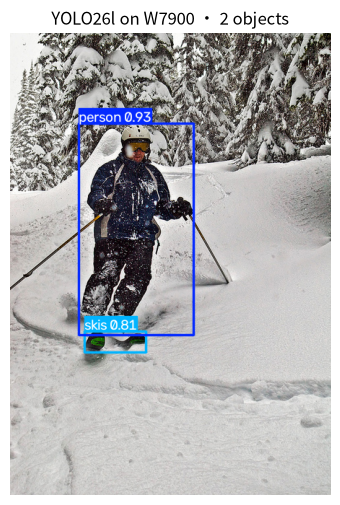

In [6]:
import matplotlib.pyplot as plt

res = model.predict(source=str(images[0]), imgsz=640, device="cuda",
                    verbose=False)
r = res[0]
im = r.plot()                       # BGR image with boxes
n_det = len(r.boxes)
print(f"detections: {n_det}")
for c in r.boxes.cls[:10]:
    print(" -", model.names[int(c)])
plt.figure(figsize=(9, 6))
plt.imshow(im[:, :, ::-1]); plt.axis("off"); plt.title(f"YOLO26l on W7900 · {n_det} objects"); plt.show()

## 4. Try it yourself / 学生练习
**先预测再验证**：你觉得对大规模并行推理（同一张图片、同一模型），CPU 和 GPU 谁更快？快多少倍？把你的预测写在下面，然后到 Notebook 01 验证。

**Predict first, then verify**: which device will be faster for the same model and image — the AMD CPU or the W7900? Write your guess, then check it in Notebook 01.

然后修改 `STUDENT_IMAGE_INDEX`（0–119），换一张图片重新推理，观察检测类别变化。
Then change `STUDENT_IMAGE_INDEX` (0–119) to detect a different image.

my guess: GPU 大约快 100 倍


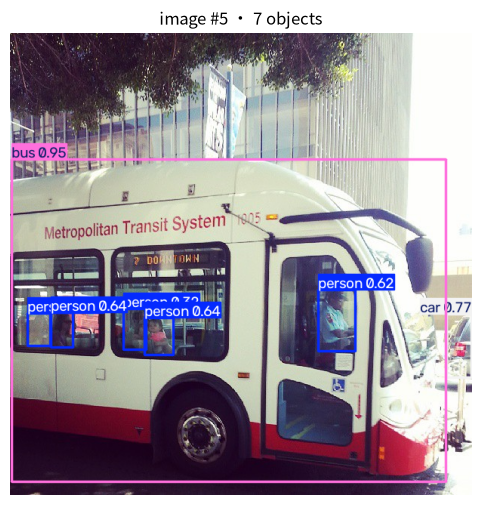

In [7]:
STUDENT_IMAGE_INDEX = 5        # <-- change me / 修改我 (0..119)

my_guess_cpu_vs_gpu = "GPU 大约快 100 倍"   # <-- write your guess / 写下预测
print("my guess:", my_guess_cpu_vs_gpu)

res = model.predict(source=str(images[STUDENT_IMAGE_INDEX]), imgsz=640,
                    device="cuda", verbose=False)
plt.figure(figsize=(9, 6))
plt.imshow(res[0].plot()[:, :, ::-1]); plt.axis("off")
plt.title(f"image #{STUDENT_IMAGE_INDEX} · {len(res[0].boxes)} objects"); plt.show()

## 5. Common mistakes / 常见错误
- **认为 OpenVINO 在驱动 W7900**：本课程中 OpenVINO 只用了它的 CPU Plugin；GPU 路径属于 ROCm/PyTorch。
  *OpenVINO is NOT driving the W7900 here*: we only use its CPU plugin; the GPU path belongs to ROCm/PyTorch.
- **把 torch.cuda 当成 NVIDIA**：ROCm 让 `torch.cuda` API 指向 AMD GPU（`torch.version.hip != None` 即为 ROCm 构建）。
  *torch.cuda is not NVIDIA-only*: under ROCm the same API targets AMD GPUs (`torch.version.hip` is set).
- **不记录模型身份就谈性能**：没有 SHA256、类别数和任务类型的“加速比”无法复核。
  *Performance claims without model identity* (sha256/classes/task) cannot be verified.


**Takeaway / 一句话总结**
> 性能实验从“确认设备与模型身份”开始——CPU 型号、GPU 架构、运行时版本、权重 SHA256，一个都不能少。
> Every performance experiment starts with verified hardware and a > verified model identity — CPU model, GPU arch, runtime versions and > the weight SHA256.

<!-- DAY2_SUBMISSION_NOTE -->

### 我的作业结论 / My submission notes

**预测 vs 实测 / Prediction vs measurement**
- 我原来猜：`GPU 大约快 100 倍`（cell 11 已打印 `my guess: GPU 大约快 100 倍`）。
- 这一份**不计时**，只验环境；真正的秒表在 01 号：CPU 200.6 ms / GPU 13.1 ms，**只快 15.31 倍**，所以这个猜测**猜错得很远**。

**一段话 / Why, how much, at what cost, how do I know**
> 这一份不测速度，只做三件事：确认机器是什么、模型是真的、图能认出来。机器是 AMD EPYC 9334（64 核）+ Radeon PRO W7900D（`gfx1100`），软件是 ROCm 版 PyTorch 2.12.0 + OpenVINO 2026.4.1。官方 `yolo26l.pt` 53.2 MB，sha256 对得上，样例图检出了 `person` 和 `skis`，说明环境能跑通。我在这份里猜「GPU 大约快 100 倍」，先留着，等 01 号用秒表去验。证明在 cell 1～11 的输出里。

**证据 / Evidence**：cell 1～11 的输出（设备、torch 版本、权重 sha256、样例图检出结果）。